# RQ3 Analysis: Type-Token Ratio (TTR)

Compares the lexical diversity (Type-Token Ratio) of human-written vs. LLM-generated PR descriptions.

- Uses `nltk.tokenize.word_tokenize` (academic standard) to tokenize text.
- TTR = number of unique tokens (types) / total number of tokens.
- Compares across models and prompt context variations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.tokenize import word_tokenize
from scipy.stats import mannwhitneyu, kruskal
import scikit_posthocs as sp

In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

In [8]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']
Human entries: 308, AI entries: 5528


## 2. Compute Type-Token Ratio (TTR)

In [8]:
def compute_ttr(text):
    """Compute Type-Token Ratio for a given text using nltk word_tokenize."""
    if pd.isna(text) or str(text).strip() == '':
        return np.nan
    text = str(text)
    tokens = word_tokenize(text.lower())
    if len(tokens) == 0:
        return np.nan
    types = set(tokens)
    return len(types) / len(tokens)

In [9]:
# Apply to both subsets
human_df['ttr'] = human_df['text'].apply(compute_ttr)
ai_df['ttr'] = ai_df['text'].apply(compute_ttr)

In [11]:
# Combine for analysis
combined_df = pd.concat([human_df, ai_df], ignore_index=True)
combined_df['source'] = combined_df['entry_type'].map({'human': 'Human', 'ai': 'AI'})
combined_df = combined_df.dropna(subset=['ttr'])

In [12]:
print("TTR metrics computed.")
print(f"Combined dataset size: {len(combined_df)}")
display(combined_df[['entry_type', 'model', 'text', 'ttr']].head(10))

TTR metrics computed.
Combined dataset size: 5836


,entry_type,model,text,ttr
0,human,Human,Fixes #8873 \r\n\r\n\r\n<!-- \r\n- Go through ...,0.491892
1,human,Human,"Implements #1516. Selected fields (`ISBN`, `UR...",0.681818
2,human,Human,"Fixes #8108 \r\n\r\nTheoretically works, but n...",0.521569
3,human,Human,Fixes #3905\r\n\r\n<!-- describe the changes y...,0.588235
4,human,Human,Fixes #2676\r\n,1.000000
5,human,Human,Fixes #8654\r\nThis allows for the right click...,0.506726
6,human,Human,# Changed database structure: table names are ...,0.398204
7,human,Human,See #2789.\r\n> JabRef version 4.0.0-beta on W...,0.840909
8,human,Human,Fixes #3584\r\n\r\n(No changelod needed as thi...,0.633929
9,human,Human,…tting down\r\n\r\nFixes #2486. Unregistering ...,0.821429


## 3. Descriptive Statistics: Human vs AI (Overall)

In [13]:
print(f"\n{'='*60}")
print("  Type-Token Ratio — Descriptive Statistics")
print(f"{'='*60}")


  Type-Token Ratio — Descriptive Statistics


In [14]:
stats = combined_df.groupby('source')['ttr'].describe()
stats['median'] = combined_df.groupby('source')['ttr'].median()
display(stats)

,count,mean,std,min,25%,50%,75%,max,median
source,,,,,,,,,
AI,5528.0,0.694275,0.138042,0.277174,0.590224,0.682446,0.785714,1.0,0.682446
Human,308.0,0.625805,0.137970,0.398204,0.530379,0.595418,0.661007,1.0,0.595418


In [15]:
for src in ['Human', 'AI']:
    vals = combined_df[combined_df['source'] == src]['ttr']
    q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
    print(f"  {src}: Q1={q1:.4f}, Median={vals.median():.4f}, Q3={q3:.4f}, IQR={q3 - q1:.4f}")

  Human: Q1=0.5304, Median=0.5954, Q3=0.6610, IQR=0.1306
  AI: Q1=0.5902, Median=0.6824, Q3=0.7857, IQR=0.1955


## 4. Descriptive Statistics: By Model

In [16]:
print(f"\n{'='*60}")
print("  Type-Token Ratio — By Model")
print(f"{'='*60}")


  Type-Token Ratio — By Model


In [17]:
stats_model = combined_df.groupby('model')['ttr'].describe()
stats_model['Median'] = combined_df.groupby('model')['ttr'].median()
stats_model['Q1'] = combined_df.groupby('model')['ttr'].quantile(0.25)
stats_model['Q3'] = combined_df.groupby('model')['ttr'].quantile(0.75)
stats_model['IQR'] = stats_model['Q3'] - stats_model['Q1']

In [18]:
display(stats_model[['count', 'mean', 'std', 'Median', 'Q1', 'Q3', 'IQR']].rename(columns={'count': 'Count', 'mean': 'Mean', 'std': 'Std'}))

,Count,Mean,Std,Median,Q1,Q3,IQR
model,,,,,,,
Human,308.0,0.625805,0.137970,0.595418,0.530379,0.661007,0.130627
Qwen/Qwen2.5-72B-Instruct,1842.0,0.703763,0.095002,0.701299,0.637397,0.768248,0.130852
gpt-5-mini-2025-08-07,1842.0,0.577248,0.081404,0.568244,0.518519,0.627907,0.109388
meta-llama/llama-3.1-70b-instruct,1844.0,0.801697,0.127230,0.800000,0.710431,0.900000,0.189569


## 5. Statistical Testing & Effect Size

In [19]:
def cliffs_delta(lst1, lst2):
    """Compute Cliff's Delta effect size."""
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y: dom += 1
            elif x < y: dom -= 1
    return dom / (m * n)

In [20]:
def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147: return "Negligible"
    elif d < 0.33: return "Small"
    elif d < 0.474: return "Medium"
    else: return "Large"

In [21]:
model_results = []

In [22]:
human_ttr = combined_df[combined_df['source'] == 'Human']['ttr'].values

In [23]:
for model in ai_df['model'].unique():
    model_data = ai_df[ai_df['model'] == model]

    for metric, human_vals in [('Type-Token Ratio', human_ttr)]:
        col = 'ttr'
        ai_vals = model_data[col].values

        stat, p = mannwhitneyu(human_vals, ai_vals, alternative='two-sided')
        cd = cliffs_delta(human_vals.tolist(), ai_vals.tolist())

        model_results.append({
            'Model': model,
            'Metric': metric,
            'Human Mean': np.mean(human_vals),
            'Model Mean': np.mean(ai_vals),
            'Human Median': np.median(human_vals),
            'Model Median': np.median(ai_vals),
            'U-Statistic': stat,
            'p-value': p,
            'Significant': 'Yes' if p < 0.05 else 'No',
            "Cliff's Delta": round(cd, 4),
            'Effect Size': interpret_cliffs_delta(cd)
        })

In [24]:
models = ai_df['model'].unique()

In [25]:
print(models)
model_results_df = pd.DataFrame(model_results)
display(model_results_df)

['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']


,Model,Metric,Human Mean,Model Mean,Human Median,Model Median,U-Statistic,p-value,Significant,Cliff's Delta,Effect Size
0,meta-llama/llama-3.1-70b-instruct,Type-Token Ratio,0.625805,0.801697,0.595418,0.800000,94452.5,9.696382e-79,Yes,-0.6674,Large
1,gpt-5-mini-2025-08-07,Type-Token Ratio,0.625805,0.577248,0.595418,0.568244,333451.0,7.949907e-07,Yes,0.1755,Small
2,Qwen/Qwen2.5-72B-Instruct,Type-Token Ratio,0.625805,0.703763,0.595418,0.701299,151030.0,1.639311e-39,Yes,-0.4676,Medium


## 6. Visualizations

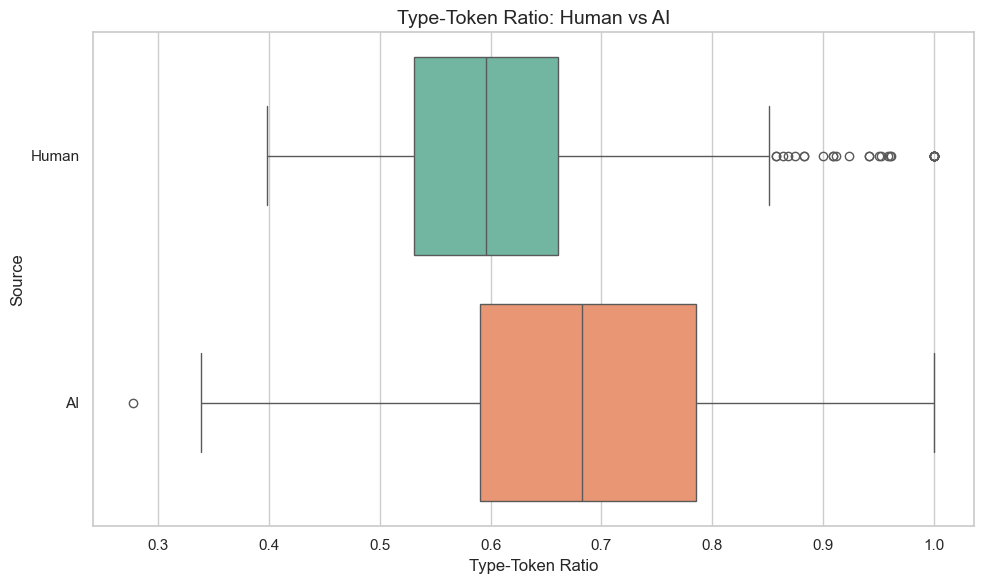

In [26]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=combined_df, x='ttr', y='source', hue='source', palette='Set2', legend=False)
plt.title("Type-Token Ratio: Human vs AI", fontsize=14)
plt.xlabel("Type-Token Ratio", fontsize=12)
plt.ylabel("Source", fontsize=12)
plt.tight_layout()
plt.show()

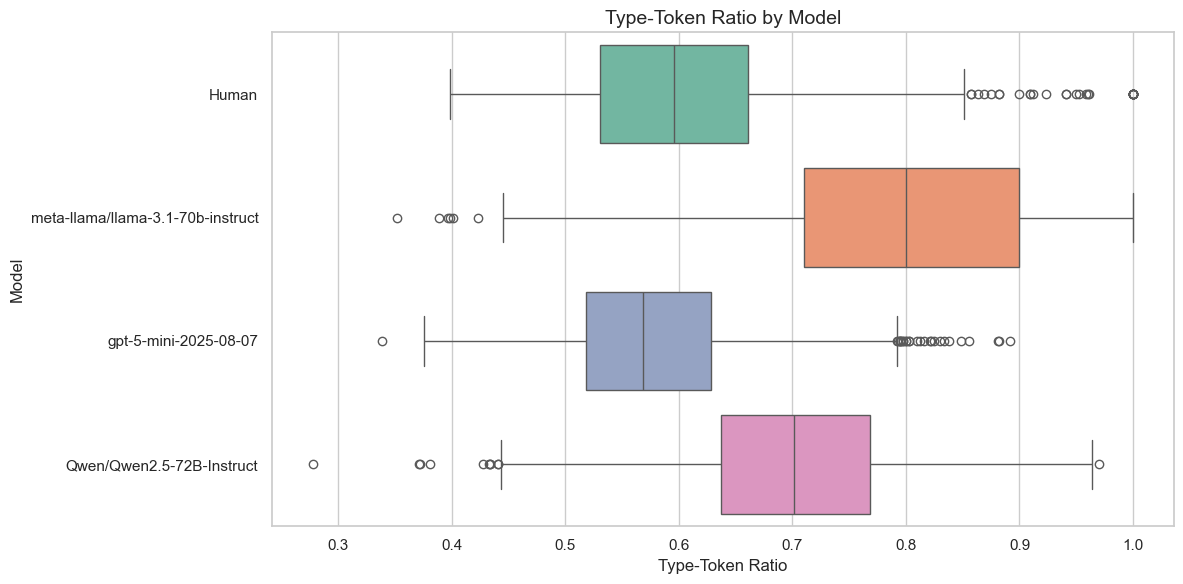

In [27]:
plt.figure(figsize=(12, 6))
order = ['Human'] + list(models)
sns.boxplot(data=combined_df, x='ttr', y='model', order=order, hue='model', palette='Set2', legend=False)
plt.title("Type-Token Ratio by Model", fontsize=14)
plt.xlabel("Type-Token Ratio", fontsize=12)
plt.ylabel("Model", fontsize=12)
plt.tight_layout()
plt.show()

## 7. TTR Boxplots by Context per LLM (with Human Baseline)

This mirrors the word-count, sentence-count, and FKGL setup:

- One panel per LLM model (stacked vertically).
- Each panel includes 6 AI context boxplots.
- A Human baseline TTR boxplot is included in each panel for direct comparison.

In [28]:
print(f"\n{'='*60}")
print("  Type-Token Ratio — By Prompt Context Variation")
print(f"{'='*60}")


  Type-Token Ratio — By Prompt Context Variation


In [29]:
# Filter to only AI data since 'human' entries don't have variation context
context_df = combined_df[combined_df['source'] == 'AI'].copy()
stats_ctx = context_df.groupby('Context_Name')['ttr'].describe()
stats_ctx['median'] = context_df.groupby('Context_Name')['ttr'].median()
display(stats_ctx)

,count,mean,std,min,25%,50%,75%,max,median
Context_Name,,,,,,,,,
File Contents,908.0,0.642261,0.120653,0.277174,0.553052,0.632653,0.703834,1.0,0.632653
File Diff,924.0,0.685003,0.134129,0.338521,0.589374,0.677969,0.767442,1.0,0.677969
Linked Issue,924.0,0.712878,0.119036,0.447699,0.625000,0.710819,0.795455,1.0,0.710819
PR Title,924.0,0.764432,0.154986,0.375258,0.613013,0.805556,0.882353,1.0,0.805556
Repo Path,924.0,0.709854,0.144498,0.436195,0.602421,0.690282,0.786188,1.0,0.690282
Without File Contents,924.0,0.650319,0.111993,0.375000,0.574556,0.648398,0.723474,1.0,0.648398


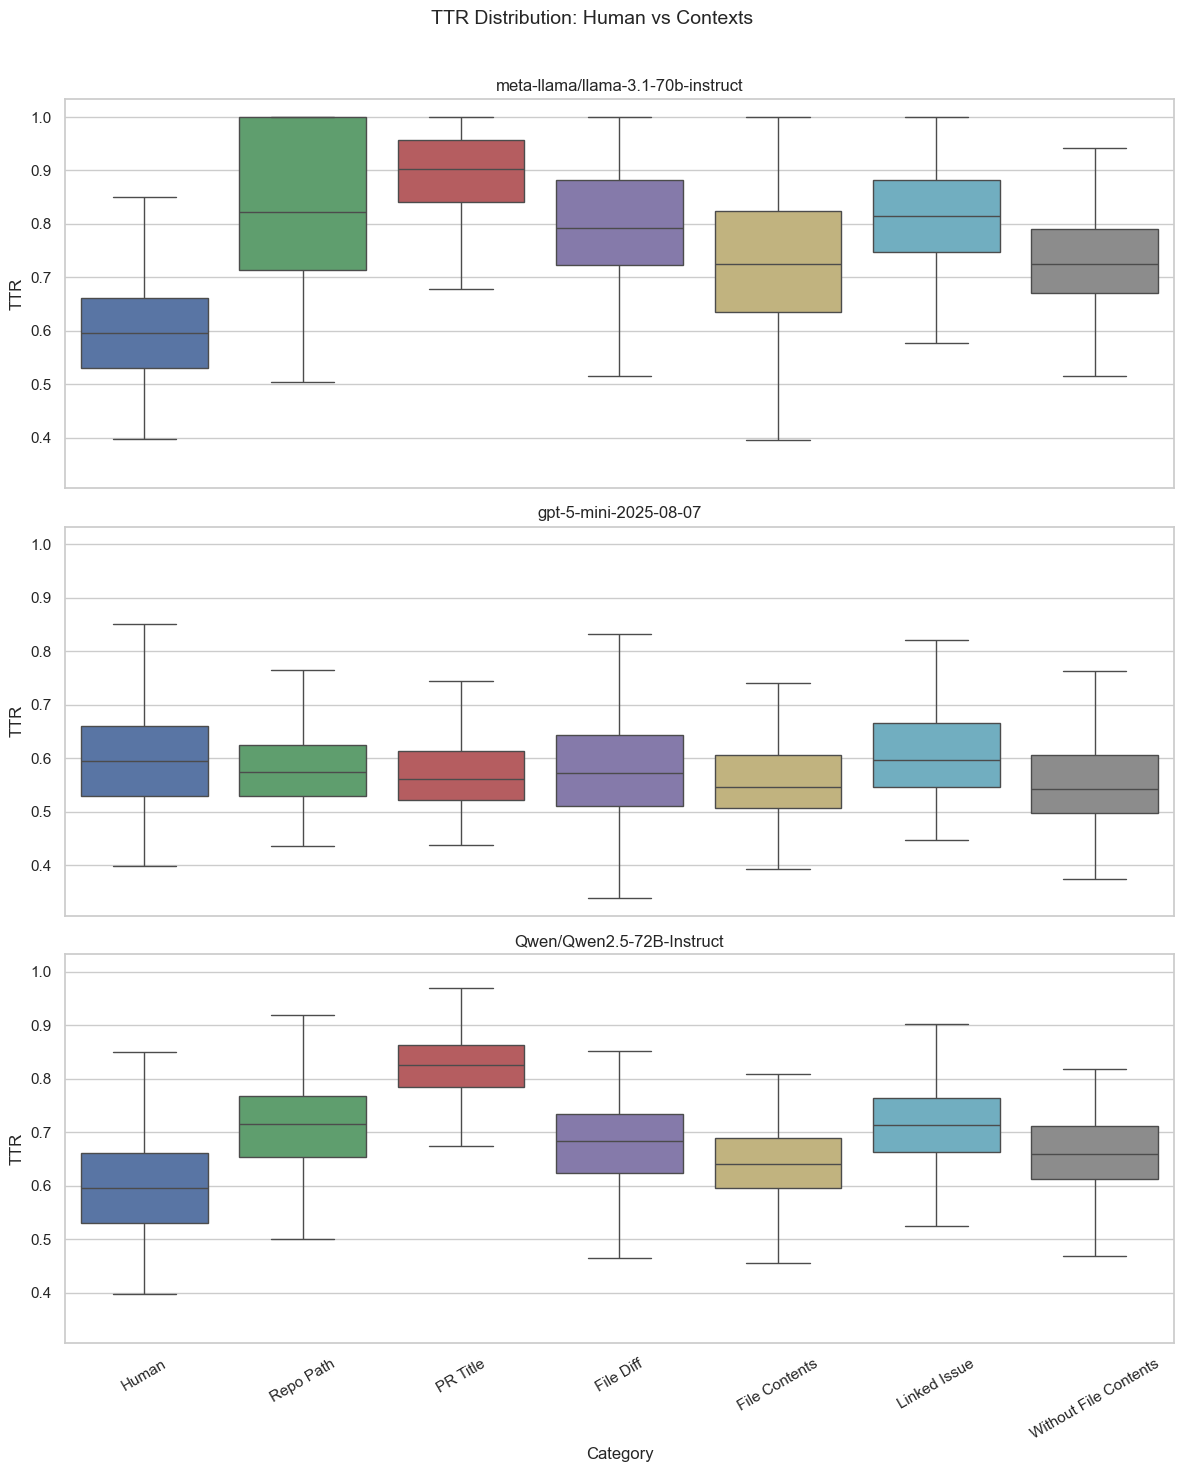

In [10]:
context_order = [
    'Repo Path',
    'PR Title',
    'File Diff',
    'File Contents',
    'Linked Issue',
    'Without File Contents'
]

llm_models = ai_df['model'].dropna().unique().tolist()
x_order = ['Human'] + context_order
palette_map = {
    'Human': '#4C72B0',
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
fig.suptitle('TTR Distribution: Human vs Contexts', fontsize=14)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]

    ai_slice = ai_df[ai_df['model'] == model][['ttr', 'Context_Name']].copy()
    ai_slice['Category'] = ai_slice['Context_Name']

    human_slice = human_df[['ttr']].copy()
    human_slice['Category'] = 'Human'

    panel_df = pd.concat([
        human_slice[['ttr', 'Category']],
        ai_slice[['ttr', 'Category']]
    ], ignore_index=True)

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='ttr',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_title(model)
    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '')
    ax.set_ylabel('TTR')
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 8. Human vs. AI Context Variations (Cliff's δ Effect Sizes per Model)

For each model and each prompt context variation, we compare the paired Human descriptions against the AI-generated descriptions using Cliff's δ effect size measure for Type-Token Ratio.

In [31]:
print(f"\n{'='*90}")
print("  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Type-Token Ratio)")
print(f"{'='*90}")


  Cliff's δ Effect Sizes: Human vs. AI Context Variations (Type-Token Ratio)


In [32]:
model_names = ai_df['model'].unique()
variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

In [33]:
rows = []
for model in model_names:
    row = {'Model': model}
    for variation in variation_names:
        # AI values for this model + variation (only paired PRs)
        ai_vals = ai_df[
            (ai_df['model'] == model) & (ai_df['Context_Name'] == variation)
        ]['ttr'].values

        # Human values for the same paired PRs
        human_vals = human_df['ttr'].values

        # Compute Cliff's delta
        delta = cliffs_delta(list(human_vals), list(ai_vals))
        interpretation = interpret_cliffs_delta(delta)

        row[variation] = f"{delta:.3f} ({interpretation})"

    rows.append(row)

In [34]:
result_df = pd.DataFrame(rows)
result_df = result_df.set_index('Model')
display(result_df)

,Repo Path,PR Title,File Diff,File Contents,Linked Issue,Without File Contents
Model,,,,,,
meta-llama/llama-3.1-70b-instruct,-0.724 (Large),-0.844 (Large),-0.662 (Large),-0.460 (Medium),-0.726 (Large),-0.586 (Large)
gpt-5-mini-2025-08-07,0.127 (Negligible),0.199 (Small),0.152 (Small),0.284 (Small),-0.010 (Negligible),0.303 (Small)
Qwen/Qwen2.5-72B-Instruct,-0.518 (Large),-0.759 (Large),-0.395 (Medium),-0.248 (Small),-0.553 (Large),-0.328 (Small)


## 9. Summary Table

In [35]:
summary_rows = []

In [36]:
for model in combined_df['model'].unique():
    vals = combined_df[combined_df['model'] == model]['ttr']
    summary_rows.append({
        'Model': model,
        'Metric': 'Type-Token Ratio',
        'N': len(vals),
        'Mean': round(vals.mean(), 4),
        'Median': round(vals.median(), 4),
        'Std': round(vals.std(), 4),
        'Min': round(vals.min(), 4),
        'Max': round(vals.max(), 4),
        'Q1': round(vals.quantile(0.25), 4),
        'Q3': round(vals.quantile(0.75), 4)
    })

In [37]:
summary_df = pd.DataFrame(summary_rows)
display(summary_df)

,Model,Metric,N,Mean,Median,Std,Min,Max,Q1,Q3
0,Human,Type-Token Ratio,308,0.6258,0.5954,0.1380,0.3982,1.0000,0.5304,0.6610
1,meta-llama/llama-3.1-70b-instruct,Type-Token Ratio,1844,0.8017,0.8000,0.1272,0.3517,1.0000,0.7104,0.9000
2,gpt-5-mini-2025-08-07,Type-Token Ratio,1842,0.5772,0.5682,0.0814,0.3385,0.8913,0.5185,0.6279
3,Qwen/Qwen2.5-72B-Instruct,Type-Token Ratio,1842,0.7038,0.7013,0.0950,0.2772,0.9697,0.6374,0.7682


In [38]:
import os
os.makedirs('outputs', exist_ok=True)

In [39]:
# Save summary to CSV
summary_df.to_csv('outputs/rq3_ttr_summary.csv', index=False)
print("\nSummary saved to outputs/rq3_ttr_summary.csv")


Summary saved to outputs/rq3_ttr_summary.csv
